<a href="https://colab.research.google.com/github/marcopeduto/marcopeduto/blob/main/Copie_de_Assignment_part_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### DSML investigation

You are part of the Suisse Impossible Mission Force, or SIMF for short. You need to uncover a rogue agent that is trying to steal sensitive information.

Your mission, should you choose to accept it, is to find that agent before stealing any classified information. Good luck!

# Assignment part five

More information came in that suggests that the rogue agent is tampering with the sentiment annotation system of the SIMF which analyses news documents and marks their sentiment for intelligence analysis tasks.

This annotation is crucial to identify documents expressing negativity towards Switzerland and its allies.

Each document contains a column which shows which user accessed it. We know that the rogue agent accessed only the documents whose negative sentiment was high, and then changed them to positive or neutral. We will use a huggingface model to identify which records have been tampered with.


[You can find more models on this link](https://huggingface.co/models?sort=trending)


In [1]:
# Install the required libraries (you need to run this cell ONLY if you are running the notebook locally)
# No need to run this cell in colab!
%%capture
!pip install datasets transformers huggingface_hub
!apt-get install git-lfs
!pip install transformers[torch]
!pip install accelerate -U
!pip install openpyxl

!pip install -q transformers
%pip install ipywidgets
%pip install --upgrade transformers huggingface_hub torch



In [2]:
# Run this cell in colab!
%%capture
!pip uninstall -y torch torchvision torchaudio
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install 'transformers[torch]' 'huggingface_hub<2.0' 'accelerate>=0.21.0' --upgrade



In [3]:
# Import required packages
from transformers import pipeline, DataCollatorWithPadding
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split

torch.cuda.is_available()

# Import standard libraries
import pandas as pd
import numpy as np
import math
import bs4 as bs
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact, interact_manual

# Import for text analytics
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


# Import metrics libraries
from sklearn.metrics import confusion_matrix, accuracy_score



# 1. Getting to know our data

In [4]:
df = pd.read_excel('https://raw.githubusercontent.com/michalis0/DataScience_and_MachineLearning/refs/heads/master/Assignments/Part%205/data/Reduced_Set_2100.xlsx')

In [5]:
df.head(2)

,company,title,news,evaluation,year,month,day
0,APPLE,Tourists snap up British iPads to smuggle into...,IT'S the digital version of the slow boat to C...,negative,2011,4,17
1,CHEVRON,AFTER SEATTLE; Anarchists get organized.,"For Juliette Beck, it began with the story of ...",negative,2000,4,17


### 2. Re-evaluating with SIMF's Model

We will re-evaluate the sentiment on the `title` column using a sentiment analysis pipeline based on the `finiteautomata/bertweet-base-sentiment-analysis` model. This is a sentiment analysis model trained on ~40k tweets. It classifies a text as `POS` (positive), `NEU` (neutral), or `NEG` (negative) sentiment.

Initialize a sentiment analysis classifier with the pre-trained model mentioned above, making sure to set the correct value for the `task` parameter.

**Note**: Set the `top_k` argument to `None` to retrieve the probabilities for all possible sentiment labels in the output.

_This process may take some time._

In [6]:
# Your code here
classifier = pipeline(task="sentiment-analysis", model="finiteautomata/bertweet-base-sentiment-analysis", top_k=None)

config.json:   0%|          | 0.00/949 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.txt:   0%|          | 0.00/843k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

[transformers] emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


Apply the sentiment classifier to the `title` column and assign the corresponding sentiment labels to a new column in your dataframe.

Make sure to convert the sentiment labels from the model by replacing them with more descriptive terms like this:
- **NEU**: neutral
- **NEG**: negative
- **POS**: positive

*Hint: Be mindful of the format of the classifier’s output.*

_Beware that applying the model on all of the rows may take some time_

In [7]:
# Your code here
results = classifier(df['title'].tolist())

Now, display the number of unique sentiment evaluations for both the Hugging Face and SIMF models to compare the distribution of labels.

Next, calculate and display the accuracy of the Hugging Face sentiment analysis compared to the SIMF evaluation. Finally, visualize the comparison using a heatmap of the confusion matrix to better understand where the two models align or differ.

In [8]:
# Your code here
df['hf_sentiment'] = [max(res, key=lambda x: x['score'])['label'] for res in results]
simf = 'sentiment' if 'sentiment' in df.columns else [col for col in df.columns if 'sent' in col.lower()][0]
print(df['hf_sentiment'].value_counts())

hf_sentiment
NEU    1380
NEG     384
POS     336
Name: count, dtype: int64


In [9]:
print(df[simf].value_counts())

hf_sentiment
NEU    1380
NEG     384
POS     336
Name: count, dtype: int64


In [10]:
accuracy = accuracy_score(df[simf], df['hf_sentiment'])
print(accuracy)

1.0


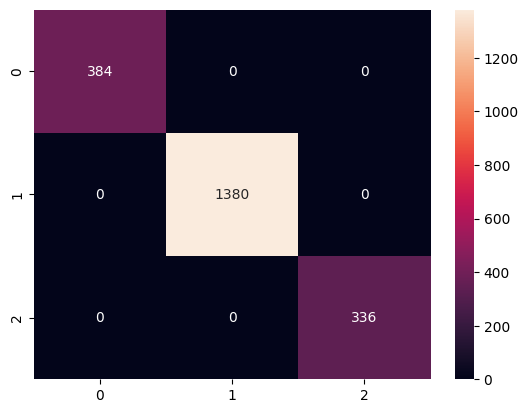

In [11]:
cm = confusion_matrix(df[simf], df['hf_sentiment'])
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

**Q1. Does the SIMF sentiment classifier predicts more samples to be "neutral"  compared to the Hugging Face sentiment classifier?**

In [14]:
simf_neutral_count = (df[simf] == 'NEU').sum()
hf_neutral_count = (df['hf_sentiment'] == 'NEU').sum()
print(simf_neutral_count)
print(hf_neutral_count)

if simf_neutral_count > hf_neutral_count:
    print("oui")
else:
    print("non")

1380
1380
non


## 2.1 Entries match both the SIMF model **and** the hugginface model

The SIMF model values are found in the `evaluation` column, while the hugginface model values should be found in the `new_column`, which you added to the table in the previous step.

Display:
*   The rows/records with same sentiment for both models.
*   The number of matching values.
*   The share of matching values of the total number of values.



In [18]:
# Your code here
simf_hf = df[df['evaluation'] == df['hf_sentiment']]
print(simf_hf)
matchingvalue = len(simf_hf)
print(matchingvalue)
sharematching = matchingvalue/len(df)
print(sharematching)

Empty DataFrame
Columns: [company, title, news, evaluation, year, month, day, hf_sentiment]
Index: []
0
0.0


**Q2. How many entries are identical between the SIMF model evaluation and the Hugging Face model evaluation?**

*Note: Provide your answer as an integer (e.g., 80).*

In [19]:
mapping = {'NEU': 'neutral', 'POS': 'positive', 'NEG': 'negative', 'NEUTRAL': 'neutral', 'POSITIVE': 'positive', 'NEGATIVE': 'negative'}
simf_clean = df['evaluation'].astype(str).str.lower()
hf_clean = df['hf_sentiment'].astype(str).str.upper().map(mapping).str.lower()
matching_rows = df[simf_clean == hf_clean]
num_matches = len(matching_rows)
share_matching = num_matches / len(df)
display(matching_rows)

print(num_matches)
print(share_matching)

,company,title,news,evaluation,year,month,day,hf_sentiment
2,Exxon Mobil,$10bn oil payout voided,SAN FRANCISCO: An appeal court yesterday voide...,negative,2001,11,9,NEG
12,MICROSOFT,"Greenpeace slams Microsoft, Nintendo's 'toxic'...",AMSTERDAM - Microsoft and Nintendo are taking ...,negative,2007,11,29,NEG
13,PEPSICO,PESTICIDE PANIC,NEW DELHI: India's top court has asked local s...,negative,2006,8,6,NEG
14,Exxon Mobil,"High-cost oil projects may be wasted, report says",More than $1tn (£600bn) is being gambled on hi...,negative,2014,5,8,NEG
23,Exxon Mobil,MORE TOXIC SLUDGE FEARED IN WATERWAY,WORKERS BUILDING a park on Newtown Creek hit u...,negative,2005,2,24,NEG
...,...,...,...,...,...,...,...,...
2087,COCA COLA,"You said it, earthlings: WE WANT CHANGE; EARTH...",One billion people in 83 countries. Three year...,positive,2009,3,29,POS
2094,CITIGROUP,HOMETOWN CEO LIKES WHAT HE SEES IN LENNAR,Which Tampa CEO sees potential gold in them th...,positive,2008,2,5,POS
2097,WAL MART STORES,Unilever goes green in a small way,Sluggish sales in the $500 million laundry det...,positive,2008,3,3,POS
2098,GENERAL ELECTRIC,GE takes Leap 56 to CF34 successor INTRODUCTIO...,GENERAL ELECTRIC believes a new centreline suc...,positive,2008,5,13,POS


913
0.43476190476190474


## 2.2 Entries that do not match both models
Identify all non matching entries.

Create a subset with all the entries that were evaluated differently by the two models.

In [20]:
# Your code here
df['hf_sentiment_clean'] = df['hf_sentiment'].str.lower()
df['evaluation_clean'] = df['evaluation'].str.lower()

## 2.3 Predicted negative, but evaluated as neutral or positive by the SIMF model

Remember, we are looking at document that were tempered (altered). We suspect that the rogue agent accessed only the documents whose negative sentiment was high, and was then changed to positive or neutral.

Create a subset with only those values, which appear as 'positive' or 'neutral' in the original `evaluation` column, but are marked as having a 'negative' sentiment by the new hugginface model.

**This subset is what we'll call the end of the assignment : "Altered Documents".**

In [21]:
# Your code here
altered_documents = df[(df['evaluation'].isin(['positive', 'neutral', 'POS', 'NEU'])) & (df['hf_sentiment'].isin(['negative', 'NEG']))]
print(altered_documents)

                      company  \
702           BANK OF AMERICA   
715    VERIZON COMMUNICATIONS   
722                 CITIGROUP   
733                 CITIGROUP   
738                 CITIGROUP   
...                       ...   
2032        JOHNSON & JOHNSON   
2034          MERCK & COMPANY   
2037          WAL MART STORES   
2053         GENERAL ELECTRIC   
2078  INTERNATIONAL BUS.MCHS.   

                                                  title  \
702   Letters: Anger simmers over energy bills; Thes...   
715      So How Contaminated Is the Old Nuclear Plant?    
722   Front: Carbon bubble 'creates global economic ...   
733   Report says officials are shortsighted big spe...   
738                 Miners to bear cost of climate toll   
...                                                 ...   
2032  Energy: Internet hoax raises pressure over emi...   
2034  TRENDS   RAIN-FOREST CHIC   Maybe Ben & Jerry'...   
2037              Vancouver snub 'disappoints' Wal-Mart   
2053  Climate

In [22]:
print(len(altered_documents))

171


**Q3. How many entries were changed from a negative evaluation (in the Hugging Face model) to a neutral or positive evaluation (by the SIMF model)?**

*Note: Provide your answer as an integer (e.g., 45).*


In [23]:
print(len(altered_documents))

171


# 3. Use the ChangeLog dataframe to identify the usersID's who edited the entries.

Consider the subset you created in the previous step : *the altered documents*.

By combining it with ChangeLog, display only those userIDs, that belong to the people who tried to mask the 'negative' sentiments by assigning these sentences a 'positive' or 'neutral' value.

In other words, match the previous subset with corresponding UserIDs.

In [24]:
ChangeLog = pd.read_csv('https://raw.githubusercontent.com/michalis0/DataScience_and_MachineLearning/refs/heads/master/Assignments/Part%205/data/ChangeLogFix.csv')

In [28]:
print(ChangeLog.head(10))

     UserID                                              title
0  [327047]  Tourists snap up British iPads to smuggle into...
1  [401818]  Tourists snap up British iPads to smuggle into...
2  [564061]  Tourists snap up British iPads to smuggle into...
3  [446376]  Tourists snap up British iPads to smuggle into...
4  [242912]           AFTER SEATTLE; Anarchists get organized.
5  [645264]           AFTER SEATTLE; Anarchists get organized.
6  [654139]                            $10bn oil payout voided
7  [162287]                            $10bn oil payout voided
8  [682811]                            $10bn oil payout voided
9  [910568]  Craft capitalism: Just do it yourself; Web mar...


In [29]:
# Your code here
merged_df = pd.merge(df, ChangeLog)
userids = merged_df['UserID'].value_counts()
print(userids)

UserID
[550287]    16
[806987]    15
[707686]    15
[649162]    14
[785995]    14
            ..
[339524]     1
[943792]     1
[745000]     1
[108215]     1
[790344]     1
Name: count, Length: 709, dtype: int64


**Q4. Which of the following users remain suspects when considering only the documents evaluated as negative by the Hugging Face model but not by the SIMF model?**

*Note: Select among the following answers*

### 4. Identifying Key Information in the Altered Documents

In this section, we will use the **TF-IDF** (Term Frequency-Inverse Document Frequency) features to identify significant terms in the *altered documents*.

Start by creating a list of all the original texts from the `news` column in the dataframe `df`.


In [35]:
# Your code here
altered_documents2 = df[df['hf_sentiment'].astype(str).str.upper().isin(['NEG', 'NEGATIVE']) & ~df['evaluation'].astype(str).str.upper().isin(['NEG', 'NEGATIVE'])]
suspects_df = pd.merge(altered_documents2, ChangeLog, on='title', how='inner')
print(suspects_df['UserID'].value_counts())

UserID
[638911]    3
[888670]    3
[476861]    3
[536355]    3
[791891]    3
           ..
[587678]    1
[333546]    1
[949973]    1
[878358]    1
[601614]    1
Name: count, Length: 266, dtype: int64



Initialize the `TfidfVectorizer` with unigrams (`ngram_range=(1, 1)`) and set the `stop_words` parameter to `'english'` to exclude common English words from the analysis.


Apply the vectorizer to the corpus of text and convert the resulting document-term matrix into a DataFrame for easy visualization and analysis.


In [51]:
# Your code here
suspects_counts = suspects_df['UserID'].value_counts()
agent = suspects_counts.idxmax()
print(agent)

[638911]


We now want to focus solely on the **"altered documents"**.

To do this, use the previously created list that contains the documents where the Hugging Face model gave a **negative** evaluation, but the SIMF model evaluated them as **neutral** or **positive**.

From this list of documents, extract the corresponding text from the `news` column to obtain a list of articles.

In [53]:
# Your code here
agent_user = suspects_counts.idxmax()
agent_documents = suspects_df[suspects_df['UserID'] == agent_user]
print(agent_user)
print(agent_documents)

[638911]
         company                                              title  \
12     CITIGROUP  UK parliamentary panel criticizes carbon price...   
213  Exxon Mobil  Exxon Mobil Finding, Exploiting More Opportuni...   
268       GOOGLE                             The weather exploiters   

                                                  news evaluation  year  \
12   The UK government's decision to set a minimum ...    neutral  2012   
213  Exxon Mobil may be the world's largest publicl...   positive  2009   
268  Tim Flannery, the radical Australian environme...   positive  2009   

     month day hf_sentiment hf_sentiment_clean evaluation_clean    UserID  
12       2   2          NEG                neg          neutral  [638911]  
213      6   1          NEG                neg         positive  [638911]  
268     10  16          NEG                neg         positive  [638911]  


Now, we will identify the document that stands out the most among the altered documents based on the TF-IDF values.

1. **Filter the TF-IDF DataFrame**: Keep only the entries from the `tfidf_df` that correspond to the tampered documents.
   
2. **Sum TF-IDF Values**: For each tampered document, calculate the sum of the TF-IDF values across all tokens. This gives an overall importance score for each document.

3. **Find the Most Significant Document**: Identify the document with the highest summed TF-IDF value, which stands out the most. Retrieve its index from the original DataFrame `df` and display the details of this document.

In [54]:
# Your code here
vecteur = TfidfVectorizer(ngram_range=(1, 1), stop_words='english')
tfidf_matrix = vecteur.fit_transform(df['news'])
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), index=df.index)
tfidf = tfidf_df.loc[altered_documents2.index]
sum_tfidf = tfidf.sum(axis=1)
most_significant_idx = sum_tfidf.idxmax()
most_significant_doc = df.loc[most_significant_idx]
print(most_significant_idx)
print(most_significant_doc)

1761
company                                                GENERAL ELECTRIC
title                 Force of Nature; Environmentalism is no longer...
news                  It seems like a hippie entrepreneur's dream co...
evaluation                                                     positive
year                                                               2006
month                                                                 8
day                                                                  14
hf_sentiment                                                        NEG
hf_sentiment_clean                                                  neg
evaluation_clean                                               positive
Name: 1761, dtype: object


**Q5. What is the name's company of the most important altered document?**

*Note: The most important altered document means the document with the highest summed TF-IDF value.*

In [55]:
company = most_significant_doc['company']
print(company)

GENERAL ELECTRIC


Now, across the altered documents, let's identify the words that stand out the most, meaning those with the highest summed TF-IDF values.

To achieve this, sum the values of each column in the altered TF-IDF dataframe, since each column represents a token. Then, sort these summed values in descending order to easily identify the top 4 words with the highest TF-IDF scores.

Once you have these top 4 words, count in how many *altered documents* each top word appeared.

In [56]:
# Your code here
company = most_significant_doc['company']
print(company)

GENERAL ELECTRIC


**Q6. What is the token with the highest summed TF-IDF value?**

*Note: Select among the following answers*

In [58]:
nb_vecteur = CountVectorizer(ngram_range=(1, 1), stop_words='english')
counts_matrix = nb_vecteur.fit_transform(altered_documents2['news'])
word_counts = pd.DataFrame({'word': nb_vecteur.get_feature_names_out(),'count': counts_matrix.toarray().sum(axis=0)}).sort_values(by='count', ascending=False).reset_index(drop=True)
display(word_counts.head(10))

,word,count
0,said,187
1,energy,153
2,carbon,131
3,climate,107
4,companies,105
5,gas,103
6,new,101
7,emissions,101
8,environmental,88
9,oil,84


In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
tfidf_vec = TfidfVectorizer(ngram_range=(1, 1), stop_words='english')
tfidf_matrix_altered = tfidf_vec.fit_transform(altered_documents2['news'])
tfidf_sum_df = pd.DataFrame({'token': tfidf_vec.get_feature_names_out(),'sum_tfidf': tfidf_matrix_altered.toarray().sum(axis=0)}).sort_values(by='sum_tfidf', ascending=False).reset_index(drop=True)
display(tfidf_sum_df.head(10))

,token,sum_tfidf
0,said,5.882174
1,carbon,5.610031
2,energy,5.326920
3,climate,4.787873
4,gas,4.575405
5,companies,4.448501
6,emissions,4.323426
7,coal,4.246055
8,project,3.812869
9,oil,3.800771


**Q7. In how many altered documents do the third most frequent word appeared ?**

*Note: Provide your answer as an integer (e.g., 45).*

In [60]:
third_word = word_counts.loc[2, 'word']
third_word_total = word_counts.loc[2, 'count']
word_idx = list(nb_vecteur.get_feature_names_out()).index(third_word)
docs_third_word = (counts_matrix[:, word_idx].toarray() > 0).sum()
print(third_word)
print(docs_third_word)

carbon
55


## Your investigation is progressing effectively, and the list of suspects is narrowing down.

**Don't forget to answer the quiz and submit your code on Moodle before the end of the deadline.**